# College Placement Analysis

Exploratory analysis of 215 MBA campus placement records, followed by a check on
whether the first result actually held up.

The notebook runs in two halves:

1. **Describe** — what does the data say?
2. **Verify** — was the headline finding correct, and is this even real data?

The second half exists because the first half produced a wrong answer.

All figures are written to `images/` with `savefig()`. Every number quoted in the
README is printed by a cell here.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")

DATA_DIR = Path("data")
IMAGE_DIR = Path("images")
IMAGE_DIR.mkdir(exist_ok=True)

BG, INK, MUTED = "#070A0F", "#FFFFFF", "#8B98A8"
GOLD, TEAL, RED, LINE = "#E8B44A", "#2DD4BF", "#FF6B6B", "#243040"

plt.rcParams.update({
    "figure.facecolor": BG, "axes.facecolor": BG, "savefig.facecolor": BG,
    "text.color": INK, "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.edgecolor": LINE, "grid.color": LINE,
    "font.family": "DejaVu Sans", "axes.grid": False,
})

print("pandas ", pd.__version__)
print("seaborn", sns.__version__)

pandas  3.0.5
seaborn 0.13.2


## 1. Load

215 records, 15 columns. Salary is blank for unplaced students, which is expected.

In [2]:
df = pd.read_csv(DATA_DIR / "placement_raw.csv")
print("Shape:", df.shape)
df.head()

Shape: (215, 15)


,sl_no,gender,ssc_p,ssc_b,hsc_p,hsc_b,hsc_s,degree_p,degree_t,workex,etest_p,specialisation,mba_p,status,salary
0,1,M,67.00,Others,91.00,Others,Commerce,58.00,Sci&Tech,No,55.0,Mkt&HR,58.80,Placed,270000.0
1,2,M,79.33,Central,78.33,Others,Science,77.48,Sci&Tech,Yes,86.5,Mkt&Fin,66.28,Placed,200000.0
2,3,M,65.00,Central,68.00,Central,Arts,64.00,Comm&Mgmt,No,75.0,Mkt&Fin,57.80,Placed,250000.0
3,4,M,56.00,Central,52.00,Central,Science,52.00,Sci&Tech,No,66.0,Mkt&HR,59.43,Not Placed,NaN
4,5,M,85.80,Central,73.60,Central,Commerce,73.30,Comm&Mgmt,No,96.8,Mkt&Fin,55.50,Placed,425000.0


## 2. Inspect

In [3]:
print("--- duplicates:", int(df.duplicated().sum()), "---")
print(df.isna().sum()[df.isna().sum() > 0])
df.dtypes.to_frame("dtype")

--- duplicates: 0 ---
salary    67
dtype: int64


,dtype
sl_no,int64
gender,str
ssc_p,float64
ssc_b,str
hsc_p,float64
hsc_b,str
hsc_s,str
degree_p,float64
degree_t,str
workex,str


## 3. Clean

Defensive only. This file has 0 duplicates and an already-numeric salary column, so
these calls remove nothing — they stay so the notebook still runs on a revised file.

In [4]:
df = df.drop_duplicates()
df["salary"] = pd.to_numeric(df["salary"], errors="coerce")
df.to_csv(DATA_DIR / "cleaned_placement.csv", index=False)

df["y"] = (df["status"] == "Placed").astype(int)
df["workex_y"] = (df["workex"] == "Yes").astype(int)

print("Rows after cleaning:", len(df))
print("Placed:", int(df.y.sum()), " Not placed:", int((1 - df.y).sum()))

Rows after cleaning: 215
Placed: 148  Not placed: 67


## 4. Describe — the first pass

The obvious questions: what is the placement rate, does work experience change it,
and how do streams compare?

In [5]:
placed = df[df.status == "Placed"]

by_workex = pd.crosstab(df.workex, df.status, normalize="index") * 100
by_stream = pd.crosstab(df.hsc_s, df.status, normalize="index") * 100

print("Overall placement rate: %.1f%%" % (df.y.mean() * 100))
print()
print("By work experience:")
print(by_workex["Placed"].round(1).to_string())
print()
print("By stream:")
print(by_stream["Placed"].round(1).to_string())
print()
print("Gap from work experience: %.1f pts" % (by_workex["Placed"]["Yes"] - by_workex["Placed"]["No"]))
print("Stream spread (best to worst): %.1f pts" % (by_stream["Placed"].max() - by_stream["Placed"].min()))

Overall placement rate: 68.8%

By work experience:
workex
No     59.6
Yes    86.5

By stream:
hsc_s
Arts        54.5
Commerce    69.9
Science     69.2

Gap from work experience: 26.9 pts
Stream spread (best to worst): 15.4 pts


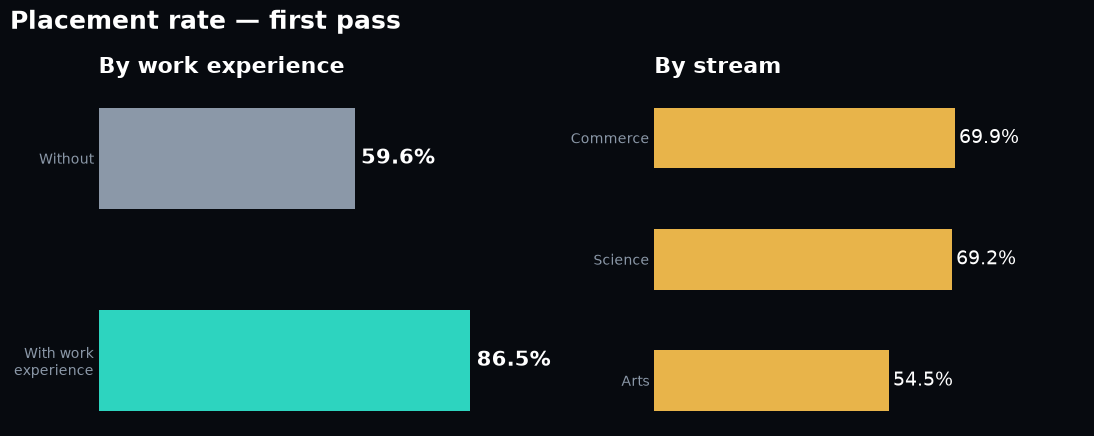

In [6]:
# fig1 — the first-pass picture
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

ax = axes[0]
vals = [by_workex["Placed"]["Yes"], by_workex["Placed"]["No"]]
ax.barh(["With work\nexperience", "Without"], vals, color=[TEAL, MUTED], height=0.5)
for i, v in enumerate(vals):
    ax.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=15, color=INK, weight="bold")
ax.set_xlim(0, 100)
ax.set_title("By work experience", fontsize=16, color=INK, weight="bold", loc="left", pad=14)
ax.set_xticks([])

ax = axes[1]
s = by_stream["Placed"].sort_values()
ax.barh(s.index, s.values, color=GOLD, height=0.5)
for i, v in enumerate(s.values):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=14, color=INK)
ax.set_xlim(0, 100)
ax.set_title("By stream", fontsize=16, color=INK, weight="bold", loc="left", pad=14)
ax.set_xticks([])

for ax in axes:
    for s_ in ax.spines.values():
        s_.set_visible(False)
    ax.tick_params(length=0)

fig.suptitle("Placement rate — first pass", fontsize=18, color=INK, weight="bold", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(IMAGE_DIR / "fig1_placement_rates.png", bbox_inches="tight", facecolor=BG)
plt.show()

## 5. Verify — rank every factor, not just two

The first pass compared work experience against **stream** only, then generalised.
The fix is to score every column on how well it separates placed from not-placed.

**AUC** is used here: 0.5 is a coin flip, 1.0 separates perfectly. It is rank-based, so
it does not depend on where a threshold is drawn.

In [7]:
def auc(x, y):
    order = np.argsort(x)
    ranks = np.empty(len(x))
    ranks[order] = np.arange(1, len(x) + 1)
    n1 = int(y.sum())
    n0 = len(y) - n1
    return (ranks[y == 1].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)


FACTORS = [
    ("ssc_p", "10th grade %"), ("hsc_p", "12th grade %"),
    ("degree_p", "Degree %"), ("etest_p", "Aptitude test %"),
    ("mba_p", "Final MBA %"), ("workex_y", "Work experience"),
]

scored = sorted(
    [(label, auc(df[col].values, df.y.values), col) for col, label in FACTORS],
    key=lambda r: r[1],
)

auc_table = pd.DataFrame(
    [{"factor": lbl, "auc": round(a, 3), "column": col} for lbl, a, col in scored]
)
auc_table

,factor,auc,column
0,Final MBA %,0.540,mba_p
1,Aptitude test %,0.571,etest_p
2,Work experience,0.633,workex_y
3,12th grade %,0.790,hsc_p
4,Degree %,0.808,degree_p
5,10th grade %,0.874,ssc_p


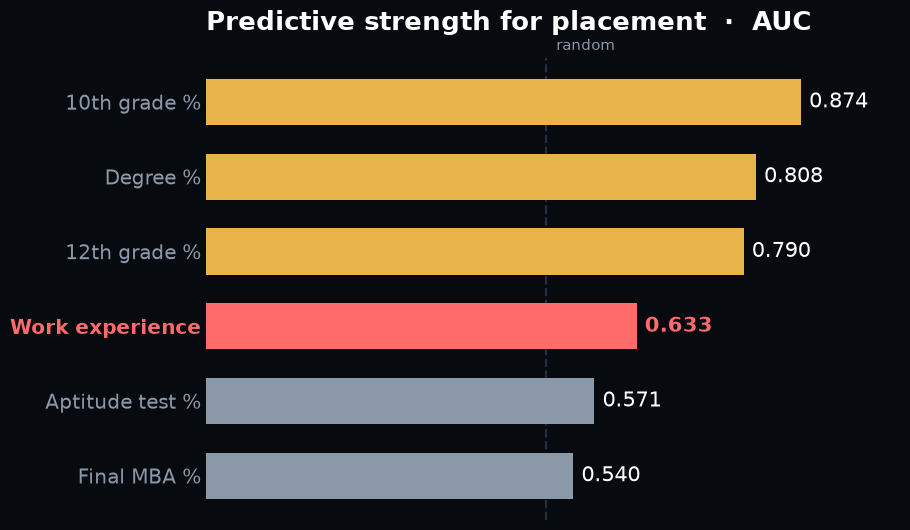

In [8]:
# fig2 — the reframe
fig, ax = plt.subplots(figsize=(9.2, 5.4))
labels = [r[0] for r in scored]
scores = [r[1] for r in scored]
cols = [RED if l == "Work experience" else (GOLD if s >= 0.75 else MUTED)
        for l, s in zip(labels, scores)]

ypos = np.arange(len(labels))
ax.barh(ypos, scores, color=cols, height=0.62)
ax.axvline(0.5, color=LINE, lw=1.6, ls="--", zorder=0)
ax.text(0.5, len(labels) - 0.25, "  random", color=MUTED, fontsize=11, va="center")

for i, (lbl, s) in enumerate(zip(labels, scores)):
    ax.text(s + 0.012, i, f"{s:.3f}", va="center", fontsize=15,
            color=RED if lbl == "Work experience" else INK,
            weight="bold" if lbl == "Work experience" else "normal")

ax.set_yticks(ypos)
ax.set_yticklabels(labels, fontsize=14.5)
for t, lbl in zip(ax.get_yticklabels(), labels):
    if lbl == "Work experience":
        t.set_color(RED)
        t.set_fontweight("bold")
ax.set_xlim(0, 1.02)
ax.set_xticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)

ax.set_title("Predictive strength for placement  ·  AUC",
             fontsize=19, weight="bold", color=INK, loc="left", pad=20)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "fig2_auc_by_factor.png", bbox_inches="tight", facecolor=BG)
plt.show()

### Work experience ranked 4th, not 1st

Three academic columns beat it. The original claim — that nothing else moved the
outcome as far — does not survive this comparison.

A second, threshold-free check: split every factor at its own median and compare the
two halves.

In [9]:
rows = []
for col, label in FACTORS:
    med = df[col].median()
    gap = (df[df[col] >= med].y.mean() - df[df[col] < med].y.mean()) * 100
    rows.append({"factor": label, "median_gap_pts": round(gap, 1)})

median_gap = pd.DataFrame(rows).sort_values("median_gap_pts", ascending=False)
median_gap

,factor,median_gap_pts
2,Degree %,44.6
0,10th grade %,44.5
1,12th grade %,34.0
3,Aptitude test %,8.7
4,Final MBA %,6.8
5,Work experience,NaN


## 6. Verify — was the effect even real?

Work experience correlated with 10th-grade marks: students who had work experience
averaged **69.9** in 10th grade against **65.9** for those who did not. Some of the
27-point gap may simply be academic ability leaking through.

The test is to compare students who already scored similarly.

In [10]:
bands = [0, 55, 62, 68, 74, 80, 100]
df["ssc_band"] = pd.cut(df.ssc_p, bands)

raw_gap = (df[df.workex_y == 1].y.mean() - df[df.workex_y == 0].y.mean()) * 100

strat = []
for b, sub in df.groupby("ssc_band", observed=True):
    yes, no = sub[sub.workex_y == 1], sub[sub.workex_y == 0]
    if len(yes) >= 3 and len(no) >= 3:
        strat.append({
            "ssc_band": str(b).replace("(", "").replace("]", ""),
            "n_with": len(yes), "n_without": len(no),
            "gap_pts": round((yes.y.mean() - no.y.mean()) * 100, 1),
        })

stratified = pd.DataFrame(strat)
print("Raw, unadjusted gap: %.1f pts" % raw_gap)
print("Mean gap within bands: %.1f pts" % stratified.gap_pts.mean())
stratified

Raw, unadjusted gap: 26.9 pts
Mean gap within bands: 20.4 pts


,ssc_band,n_with,n_without,gap_pts
0,"0, 55",10,24,15.8
1,"55, 62",5,33,54.5
2,"62, 68",14,30,26.2
3,"68, 74",18,22,12.6
4,"74, 80",15,15,13.3
5,"80, 100",12,17,0.0


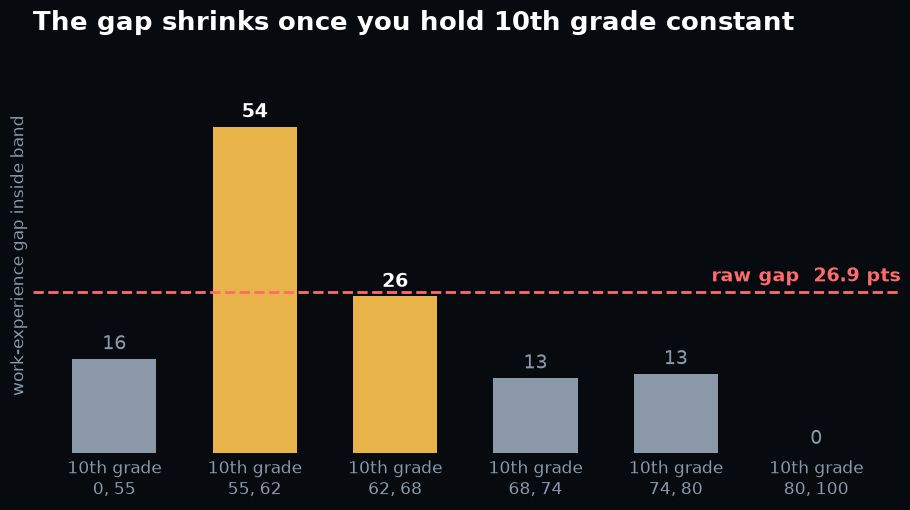

In [11]:
# fig3 — the confound
fig, ax = plt.subplots(figsize=(9.2, 5.2))
names = stratified.ssc_band
gaps = stratified.gap_pts.clip(lower=0)
ax.bar(np.arange(len(names)), gaps,
       color=[GOLD if g > 20 else MUTED for g in gaps], width=0.6)

ax.axhline(raw_gap, color=RED, lw=2, ls="--")
ax.text(len(names) - 0.4, raw_gap + 1.8, f"raw gap  {raw_gap:.1f} pts",
        color=RED, fontsize=13.5, weight="bold", ha="right")

for i, g in enumerate(gaps):
    ax.text(i, g + 1.6, f"{g:.0f}", ha="center", fontsize=14,
            color=INK if g > 20 else MUTED, weight="bold" if g > 20 else "normal")

ax.set_xticks(np.arange(len(names)))
ax.set_xticklabels([f"10th grade\n{n}" for n in names], fontsize=12.5)
ax.set_ylabel("work-experience gap inside band", fontsize=12.5)
ax.set_ylim(0, 66)
ax.set_yticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)

ax.set_title("The gap shrinks once you hold 10th grade constant",
             fontsize=19, weight="bold", color=INK, loc="left", pad=20)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "fig3_confound.png", bbox_inches="tight", facecolor=BG)
plt.show()

## 7. Verify — is this even real data?

Before claiming anything about students, check whether the file behaves like records
of real students. Three signatures say it does not.

In [12]:
# --- salary granularity ---
salary = placed.salary
all_round = bool((salary % 1000 == 0).all())
most_common = salary.value_counts().index[0]

print("Salary offers            :", len(salary))
print("Distinct values          :", salary.nunique())
print("Every value a round 1000 :", all_round)
print(f"Most common              : {most_common:,.0f} ({salary.value_counts().iloc[0]} students)")

Salary offers            : 148
Distinct values          : 45
Every value a round 1000 : True
Most common              : 300,000 (22 students)


In [13]:
# --- placement saturates at the top ---
top = df[df.ssc_p >= 80]
print(f"Students at 80% or above : {len(top)}")
print(f"Placed                    : {int(top.y.sum())}")
print(f"Rate                      : {top.y.mean() * 100:.1f}%")

Students at 80% or above : 32
Placed                    : 32
Rate                      : 100.0%


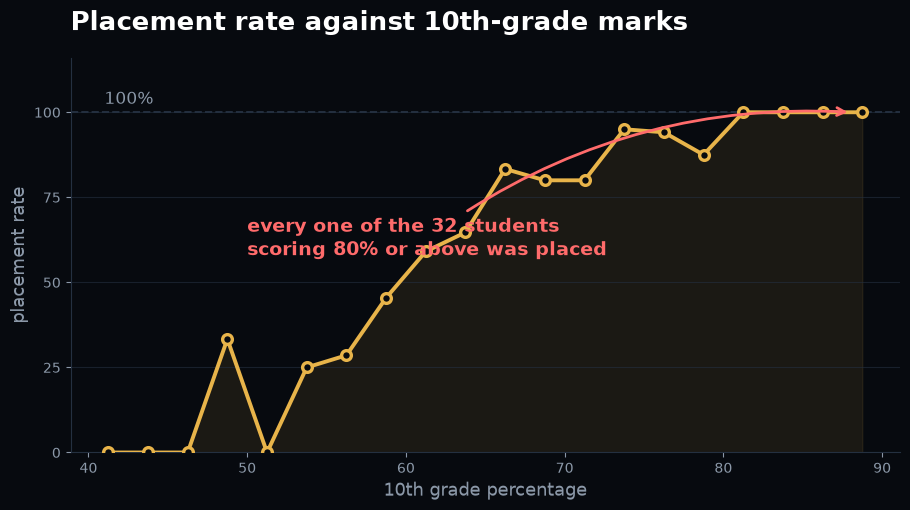

In [14]:
# --- saturation curve ---
ordered = df.sort_values("ssc_p")
edges = np.arange(40, 95, 2.5)
centres, rates = [], []
for lo, hi in zip(edges[:-1], edges[1:]):
    m = (ordered.ssc_p >= lo) & (ordered.ssc_p < hi)
    if m.sum() >= 2:
        centres.append((lo + hi) / 2)
        rates.append(ordered[m].y.mean() * 100)
centres, rates = np.array(centres), np.array(rates)

fig, ax = plt.subplots(figsize=(9.2, 5.2))
ax.plot(centres, rates, color=GOLD, lw=2.8, marker="o", ms=7,
        mfc=BG, mec=GOLD, mew=2.4, zorder=3)
ax.fill_between(centres, 0, rates, color=GOLD, alpha=0.09)
ax.axhline(100, color=LINE, lw=1.4, ls="--")
ax.text(41, 102.5, "100%", color=MUTED, fontsize=12)
ax.annotate(f"every one of the {len(top)} students\nscoring 80% or above was placed",
            xy=(88, 100), xytext=(50, 58), color=RED, fontsize=14, weight="bold",
            arrowprops=dict(arrowstyle="->", color=RED, lw=2,
                            connectionstyle="arc3,rad=-0.18"))

ax.set_xlabel("10th grade percentage", fontsize=13)
ax.set_ylabel("placement rate", fontsize=13)
ax.set_ylim(0, 116)
ax.set_yticks([0, 25, 50, 75, 100])
ax.grid(axis="y", color=LINE, lw=0.8, alpha=0.6)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.set_title("Placement rate against 10th-grade marks",
             fontsize=19, weight="bold", color=INK, loc="left", pad=20)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "fig4_saturation.png", bbox_inches="tight", facecolor=BG)
plt.show()

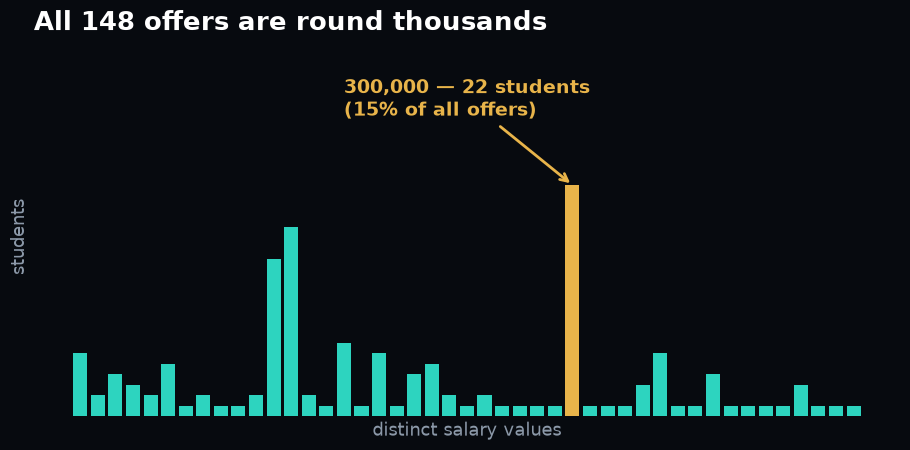

In [15]:
# --- salary grid ---
values, counts = np.unique(salary, return_counts=True)
top_idx = int(counts.argmax())

fig, ax = plt.subplots(figsize=(9.2, 4.6))
ax.bar(range(len(values)), counts,
       color=[GOLD if i == top_idx else TEAL for i in range(len(values))], width=0.8)
ax.annotate(f"{values[top_idx]:,.0f} — {counts[top_idx]} students\n({counts[top_idx] / len(salary) * 100:.0f}% of all offers)",
            xy=(top_idx, counts[top_idx]), xytext=(top_idx - 13, counts[top_idx] * 1.30),
            color=GOLD, fontsize=13.5, weight="bold",
            arrowprops=dict(arrowstyle="->", color=GOLD, lw=2))

ax.set_xlabel("distinct salary values", fontsize=13)
ax.set_ylabel("students", fontsize=13)
ax.set_ylim(0, counts.max() * 1.55)
ax.set_yticks([])
ax.set_xticks([])
for s_ in ax.spines.values():
    s_.set_visible(False)
ax.tick_params(length=0)
ax.set_title(f"All {len(salary)} offers are round thousands",
             fontsize=19, weight="bold", color=INK, loc="left", pad=20)
fig.tight_layout()
fig.savefig(IMAGE_DIR / "fig5_salary_grid.png", bbox_inches="tight", facecolor=BG)
plt.show()

## 8. Findings

Both halves, stated plainly. Every figure is printed here.

In [16]:
print("=" * 62)
print("DESCRIBE")
print("=" * 62)
print(f"Records                       : {len(df)}")
print(f"Placement rate                : {df.y.mean() * 100:.1f}%")
print(f"With work experience          : {by_workex['Placed']['Yes']:.1f}%")
print(f"Without                       : {by_workex['Placed']['No']:.1f}%")
print(f"Gap                           : {raw_gap:.1f} pts")
print(f"Stream spread                 : "
      f"{by_stream['Placed'].max() - by_stream['Placed'].min():.1f} pts")
print(f"Median salary                 : {salary.median():,.0f}")
print(f"Mean salary                   : {salary.mean():,.2f}")

print()
print("=" * 62)
print("VERIFY")
print("=" * 62)
print(f"Work experience ranks         : "
      f"{len(scored) - [l for l, a, c in scored].index('Work experience')} of {len(scored)} by AUC")
print(f"Work experience AUC           : "
      f"{[a for l, a, c in scored if l == 'Work experience'][0]:.3f}")
print(f"Strongest factor              : {scored[-1][0]} at {scored[-1][1]:.3f}")
print(f"Weakest factor                : {scored[0][0]} at {scored[0][1]:.3f}")
print(f"Gap within ssc_p bands        : {stratified.gap_pts.mean():.1f} pts (raw {raw_gap:.1f})")
print(f"Placed at 80%+ in 10th grade  : {int(top.y.sum())} of {len(top)}")

print()
print("=" * 62)
print("CONCLUSION")
print("=" * 62)
print("The 27-point work-experience gap was largely 10th-grade marks")
print("showing through, not work experience. And this is a generated")
print("teaching dataset - it does not describe real students.")

DESCRIBE
Records                       : 215
Placement rate                : 68.8%
With work experience          : 86.5%
Without                       : 59.6%
Gap                           : 26.9 pts
Stream spread                 : 15.4 pts
Median salary                 : 265,000
Mean salary                   : 288,655.41

VERIFY
Work experience ranks         : 4 of 6 by AUC
Work experience AUC           : 0.633
Strongest factor              : 10th grade % at 0.874
Weakest factor                : Final MBA % at 0.540
Gap within ssc_p bands        : 20.4 pts (raw 26.9)
Placed at 80%+ in 10th grade  : 32 of 32

CONCLUSION
The 27-point work-experience gap was largely 10th-grade marks
showing through, not work experience. And this is a generated
teaching dataset - it does not describe real students.
